# [1] 10 Rainfall at Tule Pond and the onset seasonality

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.**

1. **Daily rain at Tule Pond** from the two nearest NOAA GHCN-daily gauges,
   spliced day by day, Fremont first, then Newark (no rescaling; the overlap is
   documented). Hayward Air Terminal (18 km) is read only as the midnight-basis
   reference for the check below; it is not in the composite (Dani 2026-10-02:
   it filled only 69 days, so two gauges is the cleaner record). The morning-observer COOP gauge
   (Newark) is shifted one day earlier onto the midnight basis, and that shift
   is checked on a storm with a date in the news. Water year Oct 1 to Sep 30,
   named by the year it ends. The gauge files in `Inputs/GHCN_daily` are the
   frozen inputs; they are only downloaded if missing.
2. **The event table**: the InSAR and HRKT (bimonthly-era) events with their
   window, step and the rain around the window (`event_table.csv`).
3. **Onset seasonality**: every season-resolved onset (the 5 InSAR windows,
   the 9 array windows of 130 d or less) on the water year over the rain
   (a working figure here; the paper's Fig 3B is drawn by 11_forecast from the
   panel products this notebook saves).

The forecast of the next event and the rainfall conditioning of the onsets
are notebook 11 (11_forecast), which reads the rain table this notebook writes.

Ported from `Hayward_DISP-S1/analysis/run20_precip_ghcn.py` and
`plotting/fig_hrkt_onset_seasonality.py`.

**Outputs** (`outputs/10_rain_seasonality/`): `tulepond_daily_precip.csv`,
`wateryear_totals.csv`, the Fig 3 panel products `fig3_rain_panel.npz` and
`fig3_onset_windows.csv` (read by 11), `10_rain_stats.txt`, registry rows `10_*`.

**What to check.** Fremont and Newark agree on water-year totals to ~10 %;
Newark shifted by one day lines up with Hayward on the 11 Dec 2014 storm;
the onset windows counted against the wet season BY WINDOW, not midpoint
(November to March: wholly inside, partly, wholly outside; `10_n_wet_season_*`).
The CHECK cell tests the one-day shift of the morning-observer gauge.

In [1]:
# [2]
import os
import urllib.request
from datetime import datetime

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date, params

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

## [3] Paths and parameters

In [2]:
# [4]
notebook = "10_rain_seasonality"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


# the gauges: id -> (short name, order in the composite, day shift for morning-observer COOP gauges).
# The composite is the two nearest Tule Pond (4 and 7 km); Hayward Air Terminal (18 km) is the midnight-basis
# reference for the Newark observation-time check only. Livermore, San Jose and Oakland Museum (22 to 37 km)
# were carried as alternates until 2026-09-24 and entered no number.
ncei = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{sid}.csv"
stations = {"USC00043244": ("FREMONT", "composite-1", 0),      # COOP but on the midnight basis (checked against Hayward)
            "USC00046144": ("NEWARK", "composite-2", -1),      # COOP, morning observer (checked on the 11 Dec 2014 storm below)
            "USW00093228": ("HAYWARD_AT", "check only", 0)}    # ASOS, midnight basis: the reference for the Newark shift check
composite = ["FREMONT", "NEWARK"]
tulepond = (37.557, -121.970)      # section centre (lat, lon)
t_start = "1978-10-01"             # start of WY1979 (first HRKT survey 1979.7)
series_end = pd.Timestamp(forecast_issue_date)   # the rain series ends at the forecast issue date so the run reproduces

# the seasonality
resolvable_days = 130      # array windows longer than this do not constrain the season
wet_months = [11, 12, 1, 2, 3]   # the wet season, November to March (its share of the year's rain is computed below)
density_days, density_max = 7, 80  # the figure: running 7-day total, mm at full colour
x0, x1 = 1979.0, 2026.5           # the time axis of Fig 3: the HRKT record starts 1979.7

# the InSAR stacks at the HGIL and HRKT arrays, saved by notebook 09 for Fig 3A
stacks_file = os.path.join(paths_out["09_alignment_arrays"], "aa_insar_stacks.csv")
loma_prieta = 1989.79

events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["09_alignment_arrays"], "hrkt_aa_events.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(events_file, aa_events_file, *[os.path.join(common_paths["ghcn_dir"], f"{sid}.csv") for sid in stations])

Registry for 10_rain_seasonality: run dde37cd9, git 4013ffb+


## [5] Functions: dates and water years

Water year N runs Oct 1 of N-1 to Sep 30 of N; day of water year counts
from Oct 1 = 1.

In [3]:
# [6]
def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    dates = pd.DatetimeIndex(dates)
    year_start = pd.to_datetime(dates.year.astype(str) + "-01-01")
    next_year_start = pd.to_datetime((dates.year + 1).astype(str) + "-01-01")
    return dates.year + (dates - year_start) / (next_year_start - year_start)


def water_year(dates):
    dates = pd.DatetimeIndex(dates)
    return dates.year + (dates.month >= 10).astype(int)


def dowy(dates):
    """Day of water year: Oct 1 = 1."""
    dates = pd.DatetimeIndex(dates)
    wy_start = pd.to_datetime((water_year(dates) - 1).astype(str) + "-10-01")
    return (dates - wy_start).days + 1


def dowy_frac(decimal_years):
    """Day of water year of a decimal year (365.25-day years, good enough for plotting)."""
    return (((np.asarray(decimal_years) % 1) * 365.25 - 274) % 365.25) + 1

## [7] The daily rain composite

One value per day: Fremont where it reported, otherwise Newark. The water-year totals table records which
gauges made each year and how many days are missing.

In [4]:
# [8]
def fetch(sid):
    """One GHCN-daily gauge as a daily series (mm) from t_start, with its metadata; downloaded once if missing."""
    path = os.path.join(common_paths["ghcn_dir"], f"{sid}.csv")
    if not os.path.exists(path) or os.path.getsize(path) < 1000:
        print("downloading", sid)
        urllib.request.urlretrieve(ncei.format(sid=sid), path)
    table = pd.read_csv(path, usecols=["DATE", "LATITUDE", "LONGITUDE", "NAME", "PRCP"], low_memory=False)
    table["DATE"] = pd.to_datetime(table.DATE)
    table = table[table.DATE >= t_start]
    info = dict(name=table.NAME.iloc[0], lat=float(table.LATITUDE.iloc[0]), lon=float(table.LONGITUDE.iloc[0]),
                first=table.DATE.min().date(), last=table.DATE.max().date())
    series = table.set_index("DATE").PRCP / 10.0          # tenths of mm -> mm
    series = series[~series.index.duplicated()]
    if stations[sid][2]:
        series.index = series.index + pd.Timedelta(days=stations[sid][2])      # the COOP morning-observer shift
    return series, info


days = pd.date_range(t_start, series_end, freq="D")
rain = pd.DataFrame(index=days)
gauge_info = {}
for sid, (name, role, shift) in stations.items():
    series, info = fetch(sid)
    rain[name] = series.reindex(days)
    gauge_info[name] = dict(sid=sid, role=role, shift=shift, **info, n_valid=int(series[series.index <= series_end].notna().sum()),
                            dist_km=np.hypot((info["lat"] - tulepond[0]) * 111.19,
                                             (info["lon"] - tulepond[1]) * 111.19 * np.cos(np.radians(tulepond[0]))))
# the composite: the first gauge in the order that reported that day
rain["prcp_mm"] = np.nan
rain["src"] = "none"
for name in composite:
    take = rain.prcp_mm.isna() & rain[name].notna()
    rain.loc[take, "prcp_mm"] = rain.loc[take, name]
    rain.loc[take, "src"] = name
rain["decyear"] = decyear(rain.index)
rain["wy"] = water_year(rain.index)
rain["dowy"] = dowy(rain.index)
rain.index.name = "date"

# water-year totals, per gauge and for the composite
by_wy = rain.groupby("wy")
wy_totals = pd.DataFrame({"total_mm": by_wy.prcp_mm.sum(min_count=1), "n_days": by_wy.prcp_mm.count(),
                          "n_missing": by_wy.prcp_mm.apply(lambda x: x.isna().sum()), "max_day_mm": by_wy.prcp_mm.max(),
                          "src": by_wy.src.agg(lambda x: "+".join(sorted(set(x) - {"none"})))})
for name in [v[0] for v in stations.values()]:
    wy_totals[f"{name}_mm"] = by_wy[name].sum(min_count=1)
    wy_totals[f"{name}_ndays"] = by_wy[name].count()
wy_totals["complete"] = wy_totals.n_missing <= 20
rain.to_csv(os.path.join(out_dir, "tulepond_daily_precip.csv"), float_format="%.4f")
wy_totals.to_csv(os.path.join(out_dir, "wateryear_totals.csv"), float_format="%.1f")

stats_lines = ["10 RAIN AND SEASONALITY",
               f"rain series {days[0].date()} to {days[-1].date()} (ends at the pinned forecast issue date {forecast_issue_date})", "stations:"]
for name, info in gauge_info.items():
    stats_lines.append(f"  {name:<12} {info['sid']}  {info['name']:<38} {info['dist_km']:5.1f} km  {info['first']}..{info['last']}  "
                       f"n={info['n_valid']}  [{info['role']}, day shift {info['shift']:+d}]")
n_by_source = rain.src.value_counts()
stats_lines.append("composite = first reporting gauge in the order " + " > ".join(composite) + ": " +
                   ", ".join(f"{k} {v} d" for k, v in n_by_source.items()))
# how the gauges agree where they overlap (Hayward rows are the reference for the check, not the composite)
for gauge_a, gauge_b in [("FREMONT", "NEWARK"), ("FREMONT", "HAYWARD_AT"), ("NEWARK", "HAYWARD_AT")]:
    both_complete = wy_totals[(wy_totals[f"{gauge_a}_ndays"] >= 350) & (wy_totals[f"{gauge_b}_ndays"] >= 350)]
    ratio = both_complete[f"{gauge_a}_mm"] / both_complete[f"{gauge_b}_mm"]
    overlap = rain[[gauge_a, gauge_b]].dropna()
    overlap = overlap[overlap.index.isin(rain.index[rain.wy.isin(both_complete.index)])]
    storm_days_both = overlap[(overlap[gauge_a] >= 10) | (overlap[gauge_b] >= 10)]
    r_day = np.corrcoef(storm_days_both[gauge_a], storm_days_both[gauge_b])[0, 1] if len(storm_days_both) > 10 else np.nan
    stats_lines.append(f"  {gauge_a}/{gauge_b}: {len(both_complete)} complete WYs, WY-total ratio median {ratio.median():.2f} "
                       f"(range {ratio.min():.2f}-{ratio.max():.2f}); same-day totals on days >= 10 mm: n={len(storm_days_both)}, r={r_day:.2f}")
complete_years = wy_totals[wy_totals.complete & (wy_totals.index >= 1980) & (wy_totals.index <= 2025)]
stats_lines.append(f"WY1980-2025 complete years (n={len(complete_years)}): median {complete_years.total_mm.median():.0f} mm, "
                   f"10-90% {complete_years.total_mm.quantile(.1):.0f}-{complete_years.total_mm.quantile(.9):.0f} mm")
print("\n".join(stats_lines))

10 RAIN AND SEASONALITY
rain series 1978-10-01 to 2026-08-25 (ends at the pinned forecast issue date 2026-08-25)
stations:
  FREMONT      USC00043244  FREMONT, CA US                           4.4 km  1996-06-01..2026-08-21  n=10673  [composite-1, day shift +0]
  NEWARK       USC00046144  NEWARK, CA US                            7.2 km  1978-10-01..2021-01-15  n=15062  [composite-2, day shift -1]
  HAYWARD_AT   USW00093228  HAYWARD AIR TERMINAL, CA US             17.5 km  1998-09-19..2026-08-21  n=10191  [check only, day shift +0]
composite = first reporting gauge in the order FREMONT > NEWARK: FREMONT 10673 d, NEWARK 6724 d, none 99 d
  FREMONT/NEWARK: 16 complete WYs, WY-total ratio median 1.12 (range 0.73-1.29); same-day totals on days >= 10 mm: n=321, r=0.10
  FREMONT/HAYWARD_AT: 21 complete WYs, WY-total ratio median 0.93 (range 0.72-1.45); same-day totals on days >= 10 mm: n=384, r=0.41
  NEWARK/HAYWARD_AT: 19 complete WYs, WY-total ratio median 0.86 (range 0.70-1.64); same-day to

## [9] CHECK: the COOP observation-time shift

Newark's observer reads the gauge in the morning, so a storm is booked on
the day after it fell. Shifted one day earlier it should agree with Hayward
Air Terminal (a midnight-basis ASOS gauge) on storm days, and not before.
Then one storm with a date in the news: the "storm of the decade", Thursday
11 December 2014.

In [5]:
# [10]
newark_as_published, _ = fetch("USC00046144")
newark_as_published.index = newark_as_published.index + pd.Timedelta(days=1)          # undo the shift
hayward = rain["HAYWARD_AT"]
for label, series in (("as published", newark_as_published), ("shifted -1 d", rain["NEWARK"])):
    both = pd.concat([series.reindex(days), hayward], axis=1).dropna()
    both = both[(both.iloc[:, 0] >= 10) | (both.iloc[:, 1] >= 10)]
    print(f"Newark vs Hayward on storm days, {label}: r = {np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]:.2f} (n = {len(both)})")

# Hayward books the storm on the 11th; Newark as published on the 12th (the morning its observer read the gauge),
# on the 11th once shifted. Fremont, unshifted, also puts most of it on the 11th.
storm = pd.date_range("2014-12-10", "2014-12-12")
storm_table = pd.DataFrame({"Newark as published": newark_as_published.reindex(storm),
                            "Newark shifted -1 d": rain["NEWARK"].reindex(storm),
                            "Hayward AT (midnight)": hayward.reindex(storm),
                            "Fremont (no shift)": rain["FREMONT"].reindex(storm)}, index=storm.strftime("%a %d %b %Y"))
print("\nthe 11 Dec 2014 storm, mm per day:")
print(storm_table.round(1).to_string())

Newark vs Hayward on storm days, as published: r = -0.24 (n = 413)
Newark vs Hayward on storm days, shifted -1 d: r = 0.44 (n = 361)

the 11 Dec 2014 storm, mm per day:
                 Newark as published  Newark shifted -1 d  Hayward AT (midnight)  Fremont (no shift)
Wed 10 Dec 2014                  0.0                  1.3                    0.0                 0.0
Thu 11 Dec 2014                  1.3                 92.5                   83.3                53.3
Fri 12 Dec 2014                 92.5                  2.0                    4.1                27.9


## [11] The event catalogues

InSAR events from 04, and the HRKT array events from 09 whose survey windows
(130 d or less, the dense era) resolve the season.

In [6]:
# [12]
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_yr").reset_index(drop=True)
aa_events = pd.read_csv(aa_events_file)
aa_dense = aa_events[aa_events.window_days <= resolvable_days].reset_index(drop=True)
print(f"InSAR {len(insar_events)} events; array dense era {len(aa_dense)} events (windows <= {resolvable_days} d)")

InSAR 5 events; array dense era 9 events (windows <= 130 d)


## [13] The event table: every season-resolved onset, with its rain

One row per event: the 5 InSAR events (04) and the HRKT events of the bimonthly era (09). The onset is
equally likely anywhere in its window, so every rain quantity is given at BOTH ends of the window (never at a
midpoint): the day of the water year, the season, the water-year rain to date, and the days since the last
storm, a 3-day total of at least `storm_mm` (the storm of rule C in 11_forecast). The step is 04's or 09's
fitted amplitude with its 1-sigma error (the InSAR 95 % bootstrap bounds / 3.92). Missing rain days in the
water year up to the window are counted, so a gap in the composite shows. Written to `event_table.csv`.

In [7]:
# [14]
storm_days, storm_mm = 3, 40.0      # a storm: 3-day running total of at least 40 mm (as 11_forecast's rule C)


def to_date(decimal_years):
    """The calendar day of each decimal year (the inverse of decyear, to the nearest day)."""
    out = []
    for value in np.atleast_1d(decimal_years):
        year = int(np.floor(value))
        start, end = pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year + 1}-01-01")
        out.append((start + (value - year) * (end - start)).normalize())
    return pd.DatetimeIndex(out)


season_of_month = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
rain_filled = rain.prcp_mm.fillna(0.0)
rain_to_date = rain_filled.groupby(rain.wy).cumsum()                       # water-year rain to date, mm
missing_to_date = rain.prcp_mm.isna().astype(int).groupby(rain.wy).cumsum()
storm_total = rain_filled.rolling(storm_days, min_periods=1).sum()
last_storm = pd.Series(rain.index, index=rain.index).where(storm_total >= storm_mm).ffill()     # the last storm day so far

catalogue_rows = [("InSAR", e.onset_lo, e.onset_hi, e.amplitude_mm, (e.amp_hi - e.amp_lo) / 3.92) for e in insar_events.itertuples()]
catalogue_rows += [("HRKT array", e.onset_lo, e.onset_hi, e.amplitude_mm, e.amp_err) for e in aa_dense.itertuples()]
table_rows = []
for source, window_lo, window_hi, step_mm, step_err in catalogue_rows:
    day_lo, day_hi = to_date([window_lo])[0], to_date([window_hi])[0]
    assert rain.index[0] <= day_lo <= day_hi <= rain.index[-1], f"{source} window {day_lo.date()}-{day_hi.date()} outside the rain record"
    seasons = sorted({season_of_month[day_lo.month], season_of_month[day_hi.month]}, key=["autumn", "winter", "spring", "summer"].index)
    table_rows.append(dict(source=source, window_lo=day_lo.date(), window_hi=day_hi.date(), window_days=round((window_hi - window_lo) * 365.25),
                           step_mm=round(step_mm, 1), step_1sigma_mm=round(step_err, 1), water_year=int(rain.wy[day_lo]),
                           dowy_lo=int(rain.dowy[day_lo]), dowy_hi=int(rain.dowy[day_hi]), season="/".join(seasons),
                           wy_rain_to_date_lo_mm=round(float(rain_to_date[day_lo]), 0), wy_rain_to_date_hi_mm=round(float(rain_to_date[day_hi]), 0),
                           days_since_storm_lo=(day_lo - last_storm[day_lo]).days if pd.notna(last_storm[day_lo]) else np.nan,
                           days_since_storm_hi=(day_hi - last_storm[day_hi]).days if pd.notna(last_storm[day_hi]) else np.nan,
                           wy_missing_rain_days=int(missing_to_date[day_hi])))
event_table = pd.DataFrame(table_rows).sort_values("window_lo").reset_index(drop=True)
event_table.to_csv(os.path.join(out_dir, "event_table.csv"), index=False)
print(f"storm = {storm_days}-day total >= {storm_mm:g} mm; days since storm and rain to date at the window start (lo) and end (hi)")
print(event_table.to_string(index=False))
print("saved event_table.csv")

# the season of each onset, by its WINDOW (Dani 2026-10-02: intervals, not midpoints): the fraction of the window's
# days that fall in the wet season; an event is "inside" if the whole window does, "partly" if some of it does
wet_fraction = []
for event in event_table.itertuples():
    window_days_all = pd.date_range(event.window_lo, event.window_hi)
    wet_fraction.append(float(window_days_all.month.isin(wet_months).mean()))
event_table["wet_season_fraction"] = np.round(wet_fraction, 2)
event_table.to_csv(os.path.join(out_dir, "event_table.csv"), index=False)
is_insar = (event_table.source == "InSAR").values
wet_fraction = np.array(wet_fraction)
n_wet_inside, n_wet_partly, n_wet_outside = int((wet_fraction == 1).sum()), int(((wet_fraction > 0) & (wet_fraction < 1)).sum()), int((wet_fraction == 0).sum())
assert n_wet_inside + n_wet_partly + n_wet_outside == len(event_table)
# the wet season's share of the year's rain: median over the complete water years
in_wet = rain.index.month.isin(wet_months)
wet_share = (rain.prcp_mm[in_wet].groupby(rain.wy[in_wet]).sum() / rain.prcp_mm.groupby(rain.wy).sum()).reindex(complete_years.index)
print(f"wet season (months {wet_months}) = {100 * wet_share.median():.0f} % of the water-year rain (median of {len(wet_share)} complete years)")
print(f"onset windows: {n_wet_inside} of {len(event_table)} wholly inside the wet season ({int((wet_fraction[is_insar] == 1).sum())} of {is_insar.sum()} InSAR, "
      f"{int((wet_fraction[~is_insar] == 1).sum())} of {(~is_insar).sum()} array), {n_wet_partly} partly, {n_wet_outside} wholly outside")

storm = 3-day total >= 40 mm; days since storm and rain to date at the window start (lo) and end (hi)
    source  window_lo  window_hi  window_days  step_mm  step_1sigma_mm  water_year  dowy_lo  dowy_hi        season  wy_rain_to_date_lo_mm  wy_rain_to_date_hi_mm  days_since_storm_lo  days_since_storm_hi  wy_missing_rain_days
HRKT array 1983-01-18 1983-05-21          124      9.2             0.9        1983      110      233 winter/spring                  210.0                  710.0                   26                   22                     0
HRKT array 1985-12-14 1986-03-09           85      6.5             0.9        1986       75      160 winter/spring                  115.0                  353.0                  763                   19                     0
HRKT array 1988-04-16 1988-05-30           43      2.2             1.0        1988      199      243        spring                  180.0                  211.0                  427                  471                     

wet season (months [11, 12, 1, 2, 3]) = 85 % of the water-year rain (median of 45 complete years)
onset windows: 10 of 14 wholly inside the wet season (5 of 5 InSAR, 5 of 9 array), 2 partly, 2 wholly outside


## [15] Working figure: onsets on the water year over the rain (the paper's Fig 3B is drawn by 11_forecast)

Each water year is a column filled with the running 7-day rain total; the
water year runs down the page from Oct 1. Onsets are bars bounding the
observation window only, no midpoint marker: the event is equally likely
anywhere inside its window. Annual-survey array detections (windows of 300
to 390 d) are omitted because they do not constrain the season.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-02/qc10_onset_seasonality_wateryear_density7d_vmax80mm.png


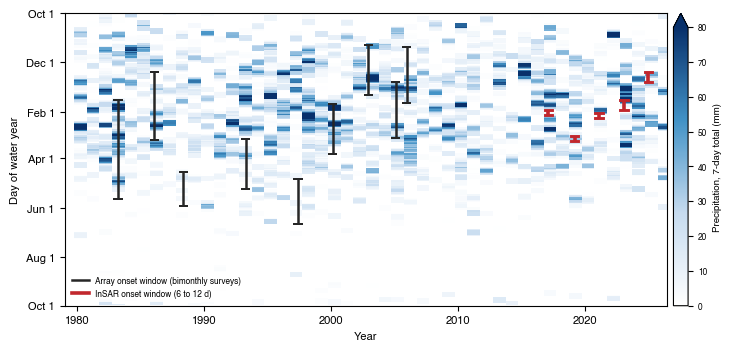

In [8]:
# [16]
def onset_bar(ax, x, day_lo, day_hi, color, lw):
    """A vertical bar from day_lo to day_hi of the water year at x, wrapping across Oct 1 if needed."""
    segments = [(day_lo, day_hi)] if day_hi >= day_lo else [(day_lo, 366), (1, day_hi)]
    for a, b in segments:
        ax.plot([x, x], [a, b], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y in (day_lo, day_hi):
        ax.plot([x - 0.28, x + 0.28], [y, y], "-", color=color, lw=lw * 0.8, zorder=5)


utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, ax = plt.subplots(figsize=(7.2, 3.4), constrained_layout=True)
rain_plot = rain[(rain.wy >= int(np.floor(x0)) + 1) & (rain.wy <= int(np.ceil(x1)))]
rain_7d = rain_plot.prcp_mm.fillna(0).rolling(density_days, min_periods=1).sum()
water_years = sorted(rain_plot.wy.unique())
rain_grid = np.full((367, len(water_years)), np.nan)          # day of water year x water year
x_edges = []
for j, wy in enumerate(water_years):
    this_year = rain_plot[rain_plot.wy == wy]
    rain_grid[this_year.dowy.values, j] = rain_7d[this_year.index].values
    x_edges.append(wy - 1 + 273 / 365.25)
x_edges.append(water_years[-1] + 273 / 365.25)
cmap = LinearSegmentedColormap.from_list("rain", ["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"])
mesh = ax.pcolormesh(np.array(x_edges), np.arange(-0.5, 367.5), rain_grid, cmap=cmap, vmin=0, vmax=density_max, shading="flat", rasterized=True, zorder=0)
for event in aa_dense.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "0.15", 1.8)
for event in insar_events.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "#C1272D", 2.6)
ax.set_xlim(x0, x1)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year")
ax.set_ylabel("Day of water year")
cb = fig.colorbar(mesh, ax=ax, pad=0.01, fraction=0.03, extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=7)
cb.ax.tick_params(labelsize=6)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.8, label="Array onset window (bimonthly surveys)"),
                   Line2D([], [], color="#C1272D", lw=2.6, label="InSAR onset window (6 to 12 d)")], fontsize=6, loc="lower left")
f_season = os.path.join(fig_dir, f"qc10_onset_seasonality_wateryear_density{density_days}d_vmax{density_max}mm.png")   # was fig3b_* (renamed 2026-10-02: not Fig 3)
fig.savefig(f_season, dpi=300)
fig.savefig(f_season.replace(".png", ".pdf"))
print("Saved figure to:", f_season)
plt.show()

## [17] The Fig 3 panels: the HRKT history and the onsets on the water year

Fig 3 (Dani 2026-10-01: the old Figs 3 and 4 combined, the survey cadence dropped) is drawn by 11_forecast,
which also has the repeat intervals and the forecast. This cell saves what its left column needs: the rain
grid on the water year, the onset windows of both catalogues, and the end of the bimonthly HRKT surveys.

In [9]:
# [18]
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hrkt_stack = pd.read_csv(stacks_file).query("code == 'HRKT'")
# the bimonthly surveys end at the last HRKT survey after which every gap to the next survey is longer than
# resolvable_days (130 d, the window the seasonality needs); the arrays were then surveyed annually until InSAR
survey_gap_days = np.diff(hrkt.year.values) * 365.25
dense_era_end = float(hrkt.year.values[np.max(np.where(survey_gap_days <= resolvable_days)[0]) + 1])
insar_start = float(hrkt_stack.date.min())
print(f"bimonthly surveys at HRKT end {dense_era_end:.2f}; annual surveys from then until the InSAR record starts {insar_start:.2f}")
windows = pd.concat([pd.DataFrame(dict(src=src, onset_yr=cat.onset_yr.values, onset_lo=cat.onset_lo.values, onset_hi=cat.onset_hi.values,
                                       dowy_lo=dowy_frac(cat.onset_lo.values), dowy_hi=dowy_frac(cat.onset_hi.values)))
                     for src, cat in (("aa_dense", aa_dense), ("insar", insar_events))], ignore_index=True)
assert len(windows) == len(aa_dense) + len(insar_events) and windows[["dowy_lo", "dowy_hi"]].notna().all().all()
windows.to_csv(os.path.join(out_dir, "fig3_onset_windows.csv"), index=False)
np.savez(os.path.join(out_dir, "fig3_rain_panel.npz"), rain_grid=rain_grid, x_edges=np.asarray(x_edges), density_days=density_days,
         density_max=density_max, x0=x0, x1=x1, loma_prieta=loma_prieta, dense_era_end=dense_era_end, insar_start=insar_start,
         rain_colours=np.array(["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"]))
print("saved fig3_onset_windows.csv and fig3_rain_panel.npz for 11_forecast")

bimonthly surveys at HRKT end 2007.44; annual surveys from then until the InSAR record starts 2016.67
saved fig3_onset_windows.csv and fig3_rain_panel.npz for 11_forecast


## [19] REGISTER

In [10]:
# [20]
stats_lines += ["", f"onset windows against the wet season (months {wet_months}, {100 * wet_share.median():.0f} % of the year's rain): "
                f"{n_wet_inside} of {len(event_table)} wholly inside, {n_wet_partly} partly, {n_wet_outside} wholly outside; "
                f"InSAR {int((wet_fraction[is_insar] == 1).sum())} of {is_insar.sum()} wholly inside"]
sidecar = REG.sidecar("10_rain", stats_lines)
REG.register("10_rain_series_start", str(days[0].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_rain_series_end", str(days[-1].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_median_mm", complete_years.total_mm.median(), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_p10_mm", complete_years.total_mm.quantile(.1), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_wy_p90_mm", complete_years.total_mm.quantile(.9), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("10_n_aa_season_resolved", len(aa_dense), "count", 0, where="Fig3 caption", cell="catalogues", sidecar=sidecar)
REG.register("10_n_events", len(event_table), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("10_n_wet_season_inside", n_wet_inside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("10_n_wet_season_partly", n_wet_partly, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("10_n_wet_season_outside", n_wet_outside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("10_n_insar_wet_season_inside", int((wet_fraction[is_insar] == 1).sum()), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("10_wet_season_rain_pct", 100 * wet_share.median(), "%", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/10_rain_seasonality/10_rain_stats.txt
  registered 10_rain_series_start = 1978-10-01 date  -> M9


  registered 10_rain_series_end = 2026-08-25 date  -> M9
  registered 10_wy_median_mm = 362 mm  -> M9


  registered 10_wy_p10_mm = 219 mm  -> M9


  registered 10_wy_p90_mm = 567 mm  -> M9
  registered 10_n_aa_season_resolved = 9 count  -> Fig3 caption


  registered 10_n_events = 14 count  -> P10
  registered 10_n_wet_season_inside = 10 count  -> P10


  registered 10_n_wet_season_partly = 2 count  -> P10


  registered 10_n_wet_season_outside = 2 count  -> P10


  registered 10_n_insar_wet_season_inside = 5 count  -> P10
  registered 10_wet_season_rain_pct = 85 %  -> P10


Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'